In [ ]:
import pandas as pd
import numpy as np
from collections import Counter
import random
import os
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageEnhance

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, losses, metrics
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [ ]:
IMAGE_PATH = Path(r"D:\DL_Finals_Roman_2702358746\3A (1)\3A\Train")


*CLASS IMBALANCE FOUND: Bacterial disease - Aeromoniasis*

In [ ]:
class_counts = {}

for cls_dir in IMAGE_PATH.iterdir():
    if cls_dir.is_dir():
        count = len([f for f in cls_dir.glob("*.*") if f.suffix.lower() in (".jpg",".jpeg",".png",".webp")])
        class_counts[cls_dir.name] = count

print("Original Counts:", class_counts)

Original Counts: {'Bacterial diseases - Aeromoniasis': 6, 'Bacterial gill disease': 250, 'Bacterial Red disease': 250, 'Fungal diseases Saprolegniasis': 250, 'Healthy Fish': 250, 'Parasitic diseases': 250, 'Viral diseases White tail disease': 250}


Classes: ['Bacterial Red disease', 'Bacterial diseases - Aeromoniasis', 'Bacterial gill disease', 'Fungal diseases Saprolegniasis', 'Healthy Fish', 'Parasitic diseases', 'Viral diseases White tail disease']


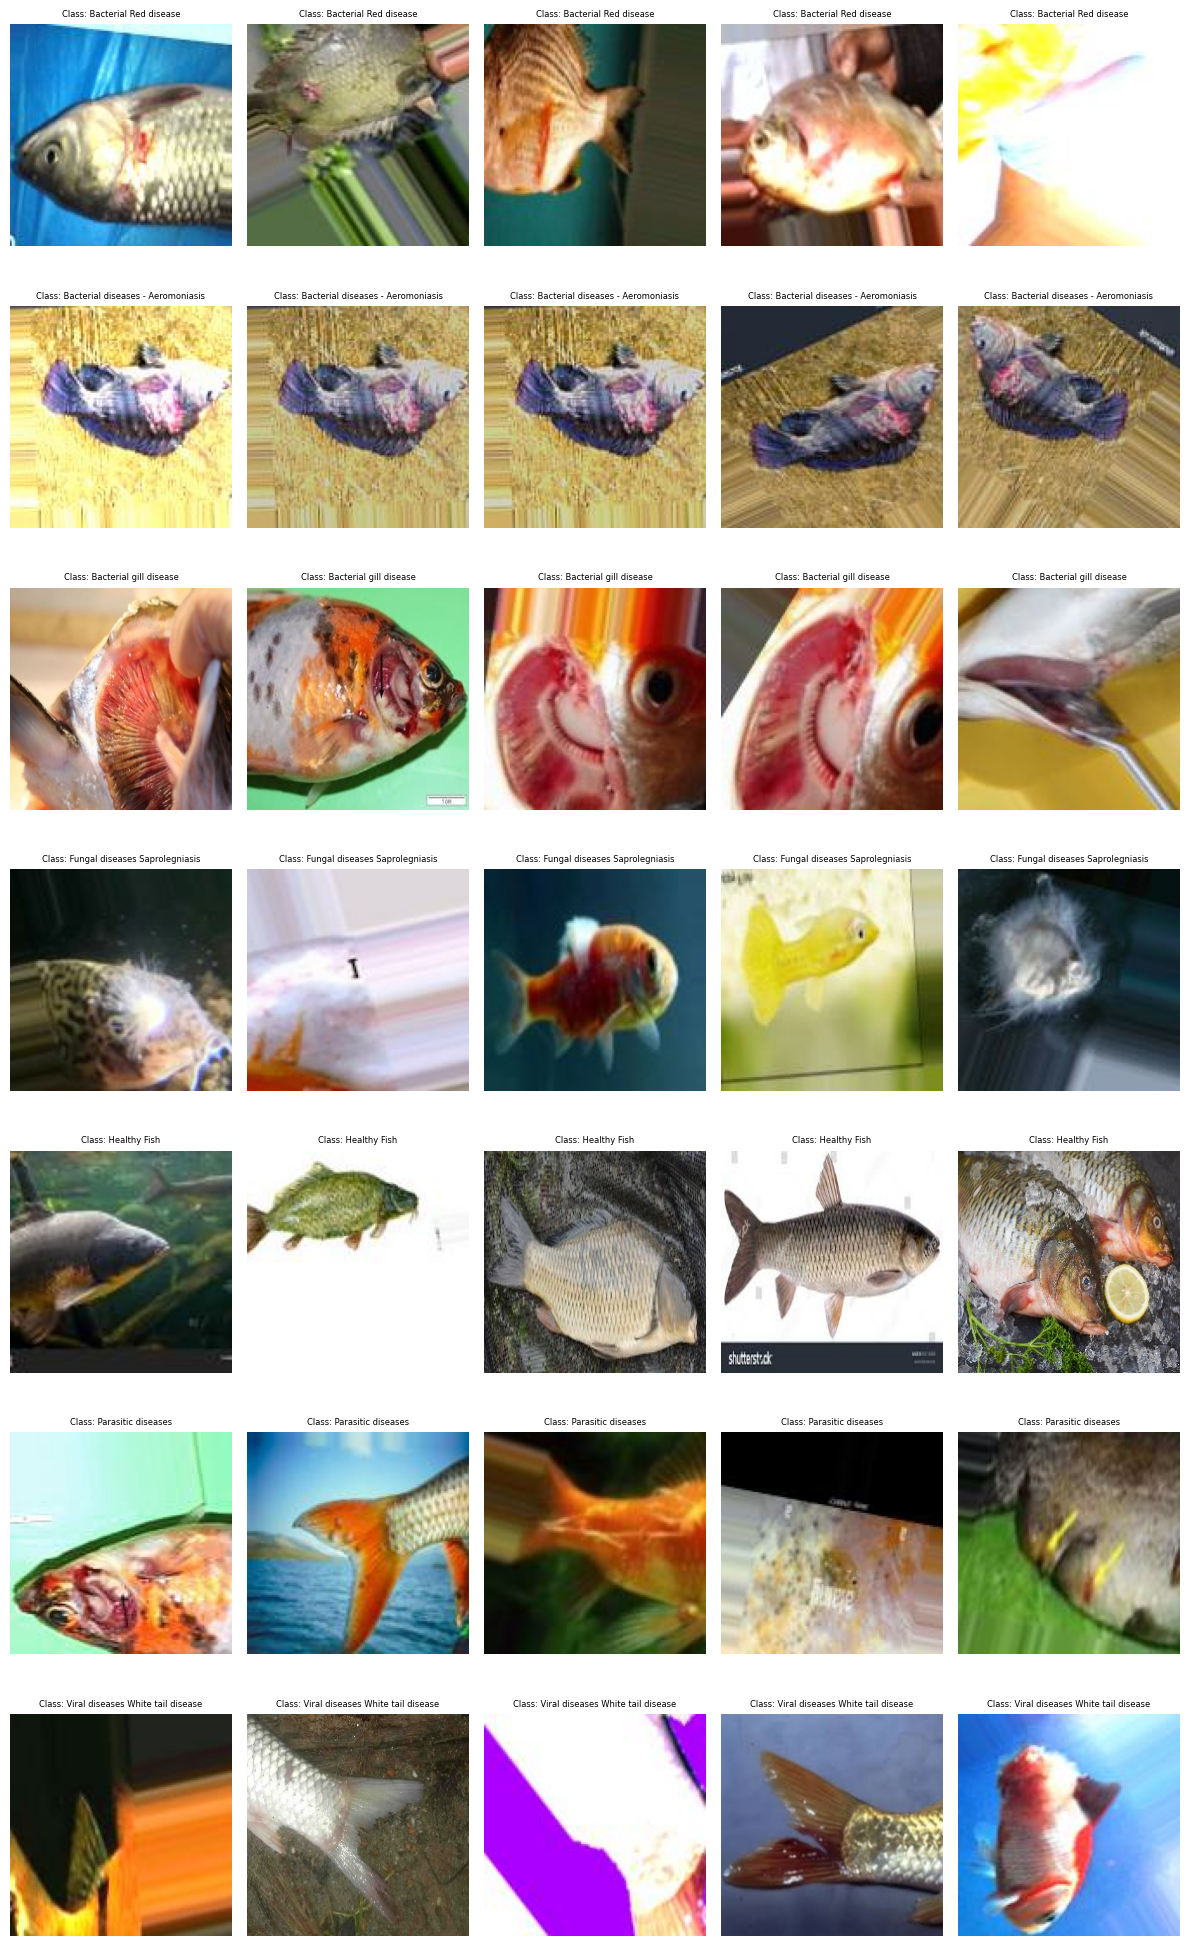

In [ ]:
classes = sorted([d.name for d in IMAGE_PATH.iterdir() if d.is_dir()])
print(f"Classes: {classes}")
fig, ax = plt.subplots(nrows=7, ncols=5, figsize=(12, 20))
p = 0
for c in classes:
    imgs = random.choices(list((IMAGE_PATH / c).glob("*.*")), k=5)
    for i, img_path in enumerate(imgs):
        img = Image.open(img_path).convert("RGB")
        ax[p, i].imshow(img)
        ax[p, i].set_title(f'Class: {c}', fontsize=6)
        ax[p, i].axis('off')
    p += 1
fig.tight_layout()
plt.show()


In [ ]:
img_path_and_label = {
    'img_path': [str(p) for p in TOTAL_IMAGE_PATH_LIST],
    'label': [p.parent.name for p in TOTAL_IMAGE_PATH_LIST]
}

df_path_and_label = pd.DataFrame(img_path_and_label)
df_path_and_label.head()


,img_path,label
0,D:\DL_Finals_Roman_2702358746\3A (1)\3A\Train\...,Bacterial diseases - Aeromoniasis
1,D:\DL_Finals_Roman_2702358746\3A (1)\3A\Train\...,Bacterial diseases - Aeromoniasis
2,D:\DL_Finals_Roman_2702358746\3A (1)\3A\Train\...,Bacterial diseases - Aeromoniasis
3,D:\DL_Finals_Roman_2702358746\3A (1)\3A\Train\...,Bacterial diseases - Aeromoniasis
4,D:\DL_Finals_Roman_2702358746\3A (1)\3A\Train\...,Bacterial diseases - Aeromoniasis


In [ ]:
from collections import Counter
import os
import seaborn as sns
import matplotlib.pyplot as plt

def plot_class_distribution(image_paths):
    class_names = [os.path.basename(os.path.dirname(p)) for p in image_paths]
    class_counts = Counter(class_names)

    print("Class Counts:", class_counts)

    plt.figure(figsize=(10,5))
    sns.barplot(
        x=list(class_counts.keys()),
        y=list(class_counts.values())
    )
    plt.xticks(rotation=45, ha='right')
    plt.title("Class Distribution")
    plt.xlabel("Class")
    plt.ylabel("Number of Images")
    plt.show()

**AFTER AUGMENTATION TO MANAGE CLASS IMBALANCE**

In [ ]:
import cv2
import numpy as np
from tqdm import tqdm

def analyze_rgb_distribution(image_paths):
    class_rgb = {}
    print("\nAnalyzing RGB Distribution per Class...")

    for img_path in tqdm(image_paths):
        class_name = os.path.basename(os.path.dirname(img_path))

        img = cv2.imread(img_path)
        if img is None:
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        r_mean = np.mean(img[:, :, 0])
        g_mean = np.mean(img[:, :, 1])
        b_mean = np.mean(img[:, :, 2])

        if class_name not in class_rgb:
            class_rgb[class_name] = {"R": [], "G": [], "B": []}

        class_rgb[class_name]["R"].append(r_mean)
        class_rgb[class_name]["G"].append(g_mean)
        class_rgb[class_name]["B"].append(b_mean)

    for class_name, color_data in class_rgb.items():

        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        sns.histplot(color_data['R'], bins=30, kde=True, color='red', ax=axes[0])
        axes[0].set_title(f"{class_name} - Red Channel")
        axes[0].set_xlim(0, 255)

        sns.histplot(color_data['G'], bins=30, kde=True, color='green', ax=axes[1])
        axes[1].set_title(f"{class_name} - Green Channel")
        axes[1].set_xlim(0, 255)

        sns.histplot(color_data['B'], bins=30, kde=True, color='blue', ax=axes[2])
        axes[2].set_title(f"{class_name} - Blue Channel")
        axes[2].set_xlim(0, 255)

        fig.suptitle(f"RGB Distribution for {class_name}", fontsize=14)
        plt.show()


Class Counts: Counter({'Bacterial diseases - Aeromoniasis': 250, 'Bacterial gill disease': 250, 'Bacterial Red disease': 250, 'Fungal diseases Saprolegniasis': 250, 'Healthy Fish': 250, 'Parasitic diseases': 250, 'Viral diseases White tail disease': 250})


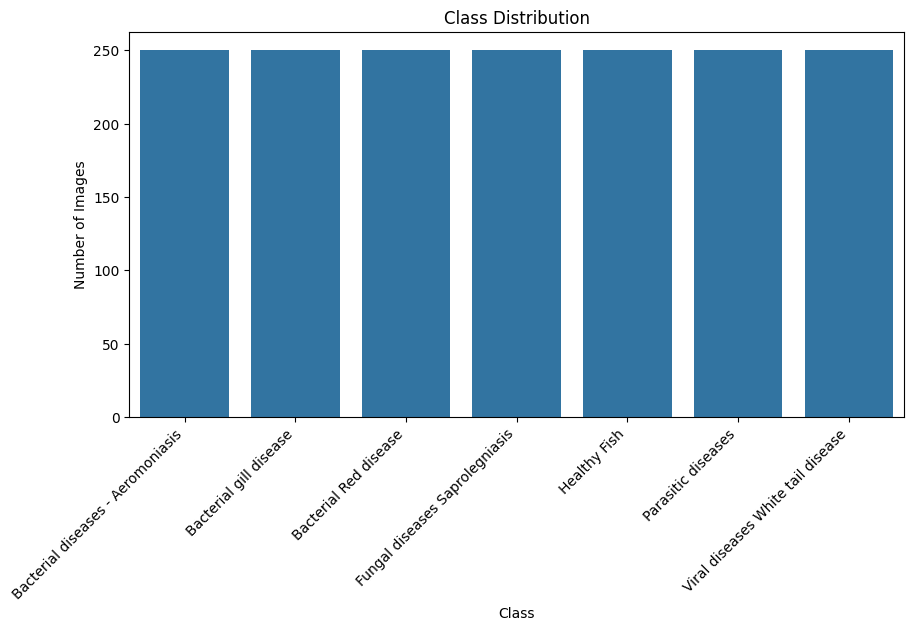


Analyzing RGB Distribution per Class...


100%|██████████| 1750/1750 [00:00<00:00, 2320.78it/s]


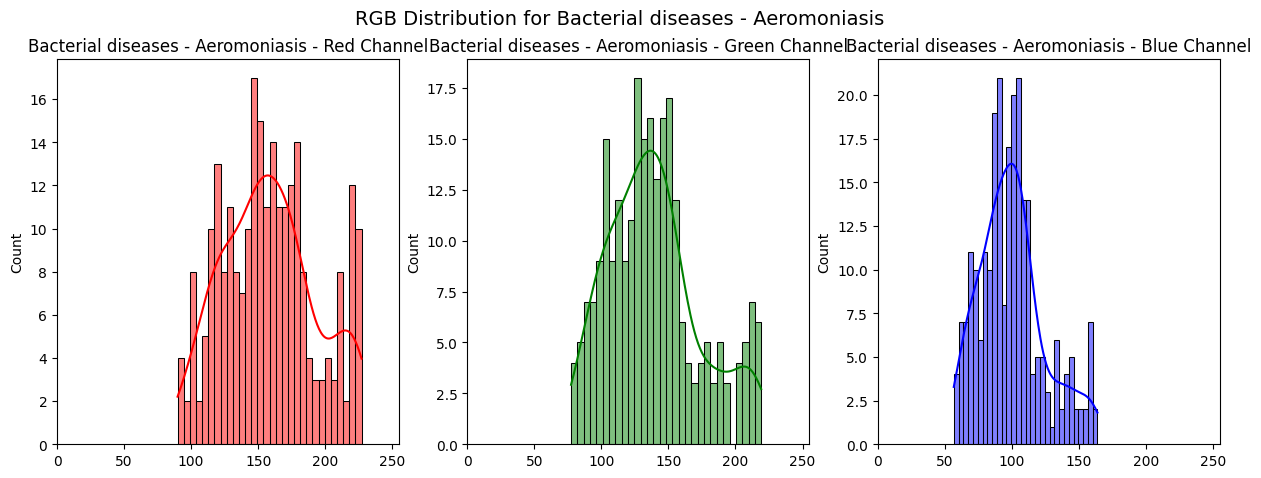

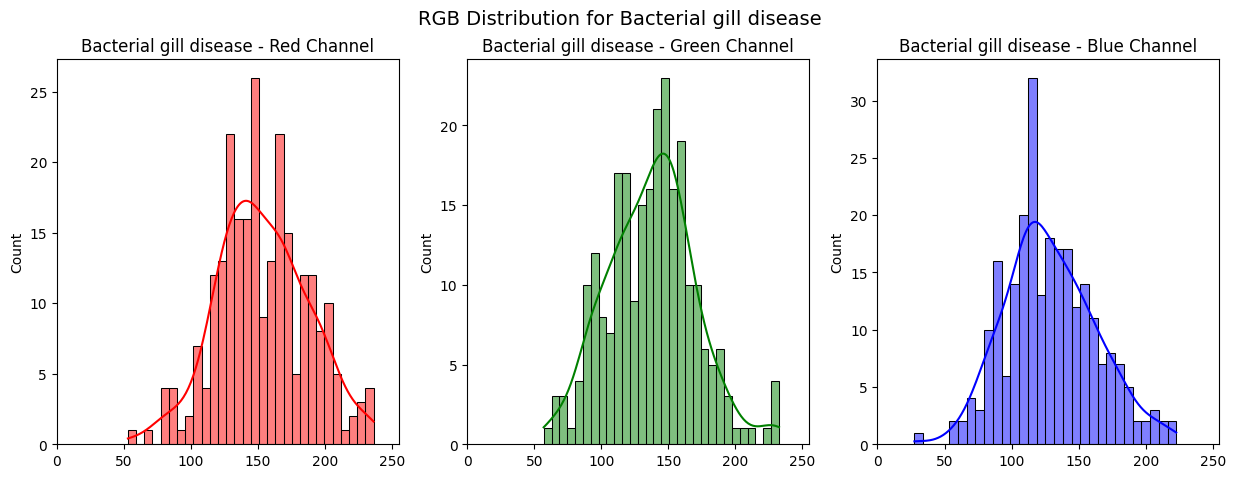

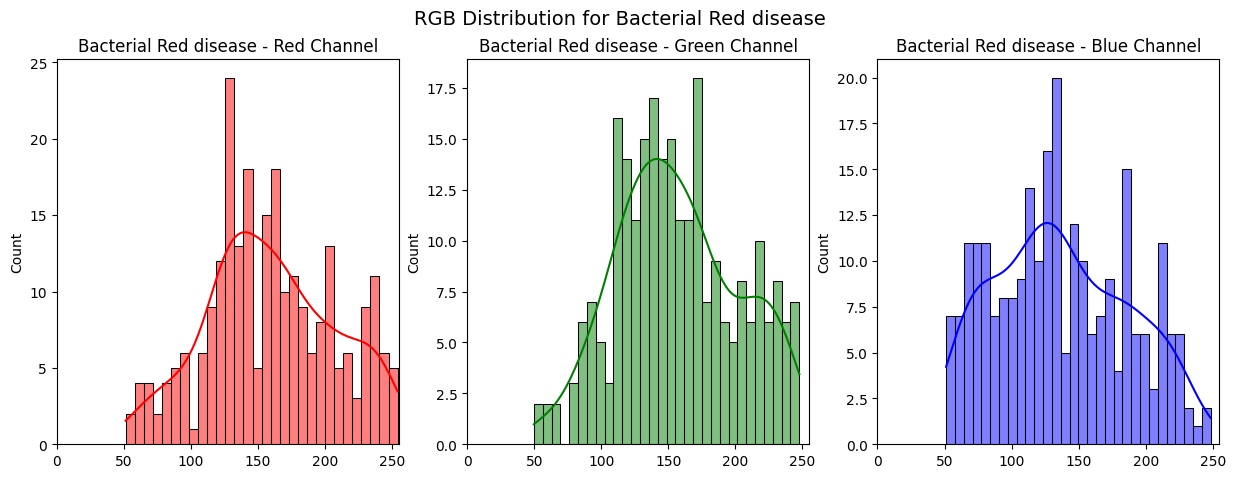

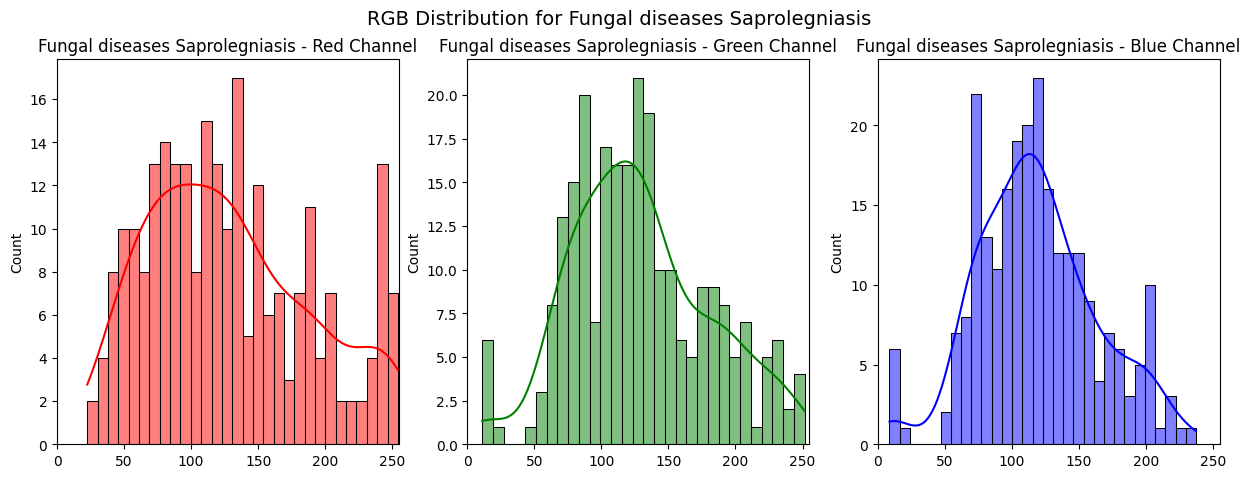

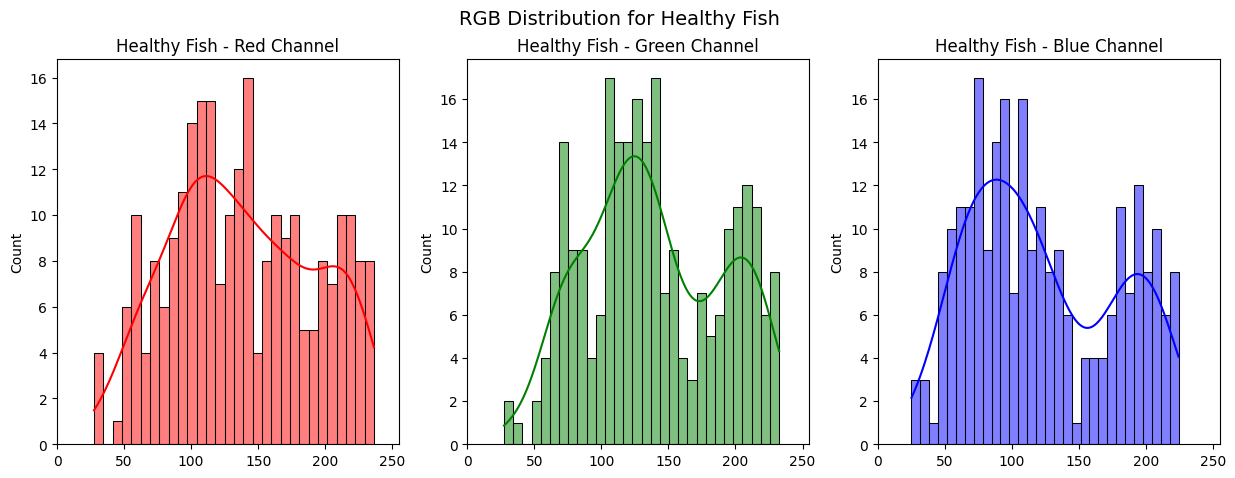

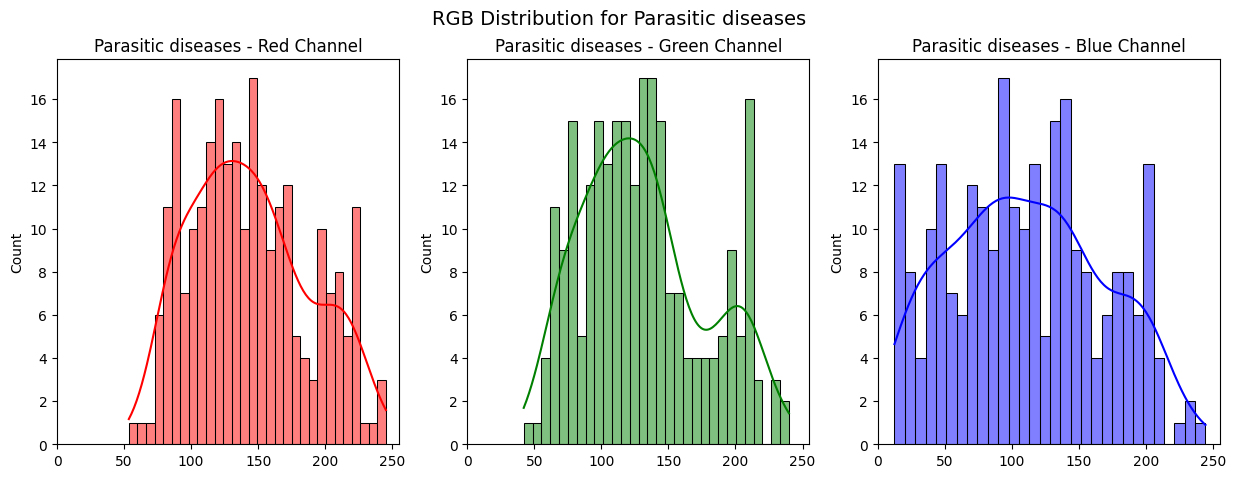

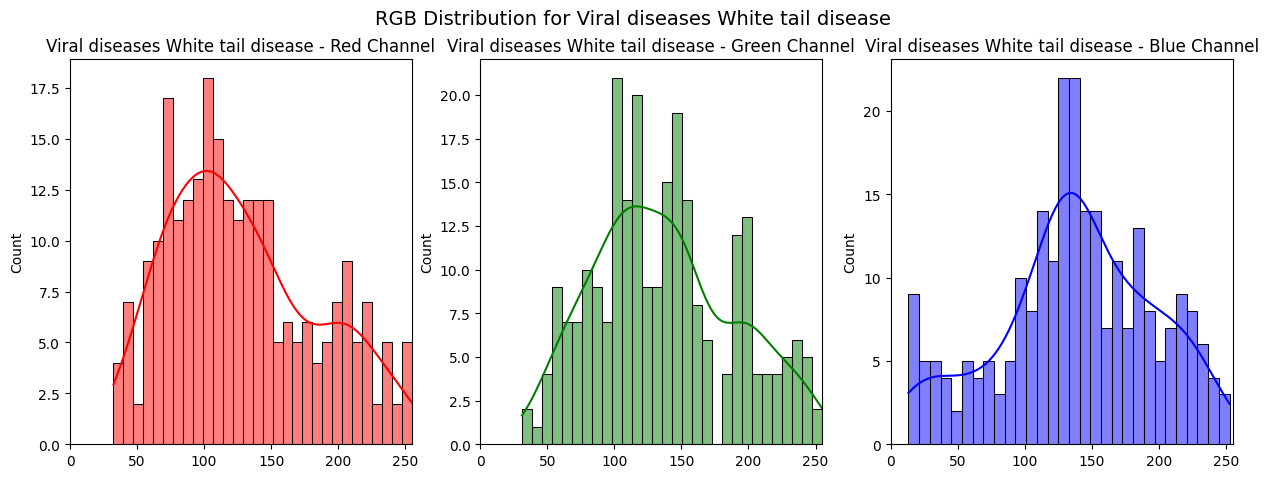

In [ ]:
plot_class_distribution(tgt_images)
analyze_rgb_distribution(tgt_images)

In [ ]:
import os
import random
from PIL import Image, ImageEnhance
import re

def augment_with_pil(train_dir, class_counts, target_count=250):
    """
    Augments classes until each reaches target_count.
    Saves images directly inside the class folder.
    Correctly handles existing 'aug_xx' and '(xx)' files.
    """

    def extract_class_index(filename, cls):
        pattern = re.compile(rf"^{re.escape(cls)} \((\d+)\)\.jpg$", re.IGNORECASE)
        match = pattern.match(filename)
        return int(match.group(1)) if match else None

    def extract_aug_index(filename):
        pattern = re.compile(r"^aug_(\d+)\.jpg$", re.IGNORECASE)
        match = pattern.match(filename)
        return int(match.group(1)) if match else None

    for cls, count in class_counts.items():
        cls_path = os.path.join(train_dir, cls)

        images = [
            f for f in os.listdir(cls_path)
            if f.lower().endswith(('.jpg','.jpeg','.png','.webp'))
        ]

        if len(images) == 0:
            print(f"[WARNING] Class {cls} has no images — skipping.")
            continue

        if count >= target_count:
            print(f"[SKIP] {cls} already has {count}")
            continue

        print(f"Augmenting '{cls}' from {count} → {target_count}")

        max_index = -1

        for f in images:
            class_idx = extract_class_index(f, cls)
            if class_idx is not None:
                max_index = max(max_index, class_idx)
                continue

            aug_idx = extract_aug_index(f)
            if aug_idx is not None:
                max_index = max(max_index, aug_idx)
                continue

        next_index = max_index + 1 if max_index != -1 else count

        img_paths = [os.path.join(cls_path, f) for f in images]
        gen_count = 0
        current_count = count

        while current_count < target_count:

            img_path = img_paths[gen_count % len(img_paths)]
            img = Image.open(img_path).convert("RGB")

            if random.random() < 0.5:
                img = img.transpose(Image.FLIP_LEFT_RIGHT)

            img = ImageEnhance.Brightness(img).enhance(random.uniform(0.7, 1.3))
            img = ImageEnhance.Contrast(img).enhance(random.uniform(0.8, 1.2))
            img = ImageEnhance.Sharpness(img).enhance(random.uniform(0.8, 2.0))

            out_name = f"{cls} ({next_index}).jpg"
            out_file = os.path.join(cls_path, out_name)

            img.save(out_file, "JPEG")

            gen_count += 1
            current_count += 1
            next_index += 1

    print("PIL Augmentation Completed.")

augment_with_pil(IMAGE_PATH, class_counts, target_count=250)

Augmenting 'Bacterial diseases - Aeromoniasis' from 6 → 250
[SKIP] Bacterial gill disease already has 250
[SKIP] Bacterial Red disease already has 250
[SKIP] Fungal diseases Saprolegniasis already has 250
[SKIP] Healthy Fish already has 250
[SKIP] Parasitic diseases already has 250
[SKIP] Viral diseases White tail disease already has 250
PIL Augmentation Completed.


In [ ]:
image_path_list = list(IMAGE_PATH.rglob("*.*"))
image_path_list = [
    p for p in image_path_list
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"] and p.is_file()
]
print(f"\nTotal Images After Augmentation = {len(image_path_list)}")



Total Images After Augmentation = 1750


In [ ]:
label_map = dict(zip(classes, range(len(classes))))
df_path_and_label['label_int'] = df_path_and_label['label'].map(label_map)

SEED = 42
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df_path_and_label['img_path'],
    df_path_and_label['label_int'],
    test_size=0.2,
    random_state=SEED,
    stratify=df_path_and_label['label_int']
)

train_df = pd.DataFrame({'filename': X_train, 'class': y_train})
test_df = pd.DataFrame({'filename': X_test, 'class': y_test})

print("Training set class distribution:", Counter(y_train))
print("Test set class distribution:", Counter(y_test))


Training set class distribution: Counter({5: 200, 3: 200, 6: 200, 2: 200, 1: 200, 0: 200, 4: 200})
Test set class distribution: Counter({4: 50, 5: 50, 0: 50, 1: 50, 2: 50, 3: 50, 6: 50})


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
train_df['class'] = train_df['class'].astype(str)
test_df['class'] = test_df['class'].astype(str)

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    class_mode='sparse',
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

test_generator = test_datagen.flow_from_dataframe(
    test_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    class_mode='sparse',
    batch_size=BATCH_SIZE,
    shuffle=False
)


Found 1397 validated image filenames belonging to 7 classes.
Found 350 validated image filenames belonging to 7 classes.


c:\Users\roman\anaconda3\envs\myenv\Lib\site-packages\keras\src\legacy\preprocessing\image.py:920: UserWarning: Found 3 invalid image filename(s) in x_col="filename". These filename(s) will be ignored.
  warnings.warn(


In [ ]:
NUM_CLASSES = len(classes)

base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224,224,3))
base_model.trainable = False  # FREEZE ALL LAYERS

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 7)              │        14,343 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,602,055 (90.03 MB)

 Trainable params: 14,343 (56.03 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=[metrics.SparseCategoricalAccuracy()]
)


In [ ]:
EPOCHS = 20

history = model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=EPOCHS
)


Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - loss: 1.5973 - sparse_categorical_accuracy: 0.4381 - val_loss: 0.8093 - val_sparse_categorical_accuracy: 0.7086
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 75s 2s/step - loss: 0.9160 - sparse_categorical_accuracy: 0.6657 - val_loss: 0.6432 - val_sparse_categorical_accuracy: 0.7514
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - loss: 0.7154 - sparse_categorical_accuracy: 0.7287 - val_loss: 0.5635 - val_sparse_categorical_accuracy: 0.7829
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 107s 2s/step - loss: 0.6283 - sparse_categorical_accuracy: 0.7695 - val_loss: 0.4435 - val_sparse_categorical_accuracy: 0.8543
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - loss: 0.5462 - sparse_categorical_accuracy: 0.7967 - val_loss: 0.4080 - val_sparse_categorical_accuracy: 0.8800
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 85s 2s/step - loss: 0.4675 - sparse_categorical_accuracy: 0.8268 - val_loss: 0.3916 - val_sparse_categorical_accuracy: 0.8571
Epoch 7/20
44/4

In [ ]:
base_model.trainable = True   # VERY IMPORTANT

for layer in base_model.layers[:-15]:
    layer.trainable = False

for layer in base_model.layers[-15:]:
    layer.trainable = True

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(train_generator, validation_data=test_generator, epochs=20)

Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accuracy: 0.9191 - loss: 0.2494 - val_accuracy: 0.9286 - val_loss: 0.2029
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 199s 5s/step - accuracy: 0.9399 - loss: 0.1909 - val_accuracy: 0.9371 - val_loss: 0.1950
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 219s 5s/step - accuracy: 0.9435 - loss: 0.1901 - val_accuracy: 0.9429 - val_loss: 0.1876
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.9542 - loss: 0.1798 - val_accuracy: 0.9400 - val_loss: 0.1787
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 119s 3s/step - accuracy: 0.9556 - loss: 0.1577 - val_accuracy: 0.9429 - val_loss: 0.1774
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 121s 3s/step - accuracy: 0.9528 - loss: 0.1598 - val_accuracy: 0.9429 - val_loss: 0.1736
Epoch 7/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 86s 2s/step - accuracy: 0.9628 - loss: 0.1449 - val_accuracy: 0.9457 - val_loss: 0.1700
Epoch 8/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 87s 2s/step - accuracy: 0.9635 - loss: 0.1449 - val_accuracy: 0.9486 - val_l

Classes: ['Bacterial Red disease', 'Bacterial diseases - Aeromoniasis', 'Bacterial gill disease', 'Fungal diseases Saprolegniasis', 'Healthy Fish', 'Parasitic diseases', 'Viral diseases White tail disease']
11/11 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step


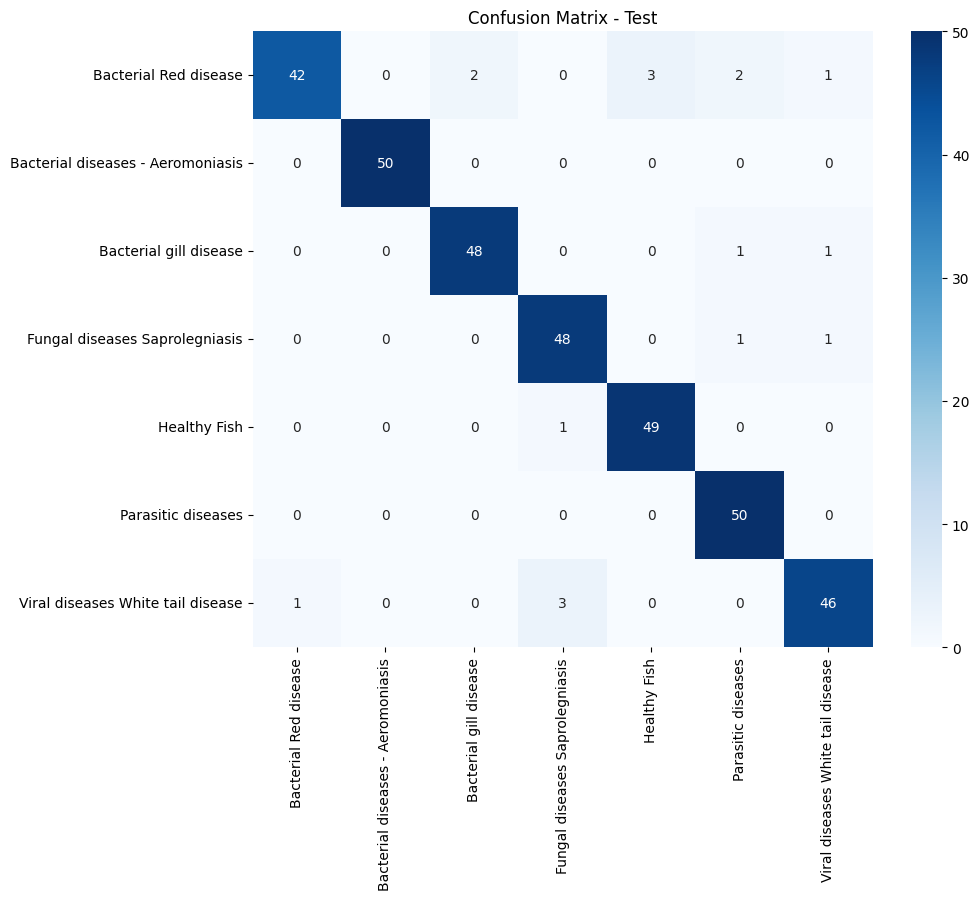

                                   precision    recall  f1-score   support

            Bacterial Red disease       0.98      0.84      0.90        50
Bacterial diseases - Aeromoniasis       1.00      1.00      1.00        50
           Bacterial gill disease       0.96      0.96      0.96        50
   Fungal diseases Saprolegniasis       0.92      0.96      0.94        50
                     Healthy Fish       0.94      0.98      0.96        50
               Parasitic diseases       0.93      1.00      0.96        50
Viral diseases White tail disease       0.94      0.92      0.93        50

                         accuracy                           0.95       350
                        macro avg       0.95      0.95      0.95       350
                     weighted avg       0.95      0.95      0.95       350

Test Accuracy: 0.9514


In [ ]:
classes = sorted([d.name for d in IMAGE_PATH.iterdir() if d.is_dir()])
print(f"Classes: {classes}")

import math
steps = math.ceil(test_generator.samples / test_generator.batch_size)
y_pred_probs = model.predict(test_generator, steps=steps)

y_pred = np.argmax(y_pred_probs, axis=1)

y_true = test_generator.classes

min_len = min(len(y_true), len(y_pred))
y_true = y_true[:min_len]
y_pred = y_pred[:min_len]

cf_mx = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10,8))
sns.heatmap(cf_mx, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues')
plt.title("Confusion Matrix - Test")
plt.show()

print(classification_report(y_true, y_pred, target_names=classes))

acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {acc:.4f}")


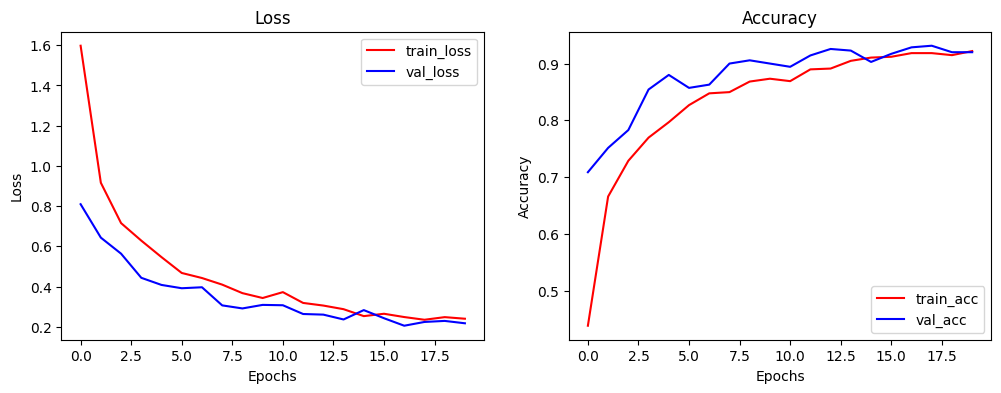

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train_loss', color='red')
plt.plot(history.history['val_loss'], label='val_loss', color='blue')
plt.title("Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['sparse_categorical_accuracy'], label='train_acc', color='red')
plt.plot(history.history['val_sparse_categorical_accuracy'], label='val_acc', color='blue')
plt.title("Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.show()


In [ ]:
print(history.history.keys())


dict_keys(['loss', 'sparse_categorical_accuracy', 'val_loss', 'val_sparse_categorical_accuracy'])


In [ ]:
from tensorflow.keras import layers, models, optimizers, losses, metrics

NUM_CLASSES = len(classes)
IMG_SHAPE = (224, 224, 3)

baseline_cnn = models.Sequential([
    # Input Layer
    layers.Input(shape=IMG_SHAPE),

    # Conv + MaxPool Block 1
    layers.Conv2D(96, kernel_size=(11,11), strides=(4,4), activation='relu', padding='valid'),
    layers.MaxPooling2D(pool_size=(3,3), strides=2),

    # Conv + MaxPool Block 2
    layers.Conv2D(256, kernel_size=(5,5), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(3,3), strides=2),

    # Conv Layers Block 3
    layers.Conv2D(384, kernel_size=(3,3), activation='relu', padding='same'),
    layers.Conv2D(256, kernel_size=(3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(3,3), strides=2),

    # Fully Connected Layers
    layers.Flatten(),
    layers.Dense(1024, activation='relu'),
    layers.Dense(1024, activation='relu'),

    # Output Layer
    layers.Dense(NUM_CLASSES, activation='softmax')
])

baseline_cnn.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     6,554,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │         7,175 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,031,111 (38.27 MB)

 Trainable params: 10,031,111 (38.27 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
train_datagen_cnn = ImageDataGenerator(
    rescale=1./255,
    rotation_range=5,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    horizontal_flip=True,

    channel_shift_range=50.0,
    brightness_range=[0.7, 1.3],

    fill_mode='nearest',
)

test_datagen_cnn = ImageDataGenerator(
    rescale=1./255
)

train_generator_cnn = train_datagen_cnn.flow_from_dataframe(
    train_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    class_mode='sparse',
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

test_generator_cnn = test_datagen_cnn.flow_from_dataframe(
    test_df,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    class_mode='sparse',
    batch_size=BATCH_SIZE,
    shuffle=False
)


Found 1397 validated image filenames belonging to 7 classes.
Found 350 validated image filenames belonging to 7 classes.


c:\Users\roman\anaconda3\envs\myenv\Lib\site-packages\keras\src\legacy\preprocessing\image.py:920: UserWarning: Found 3 invalid image filename(s) in x_col="filename". These filename(s) will be ignored.
  warnings.warn(


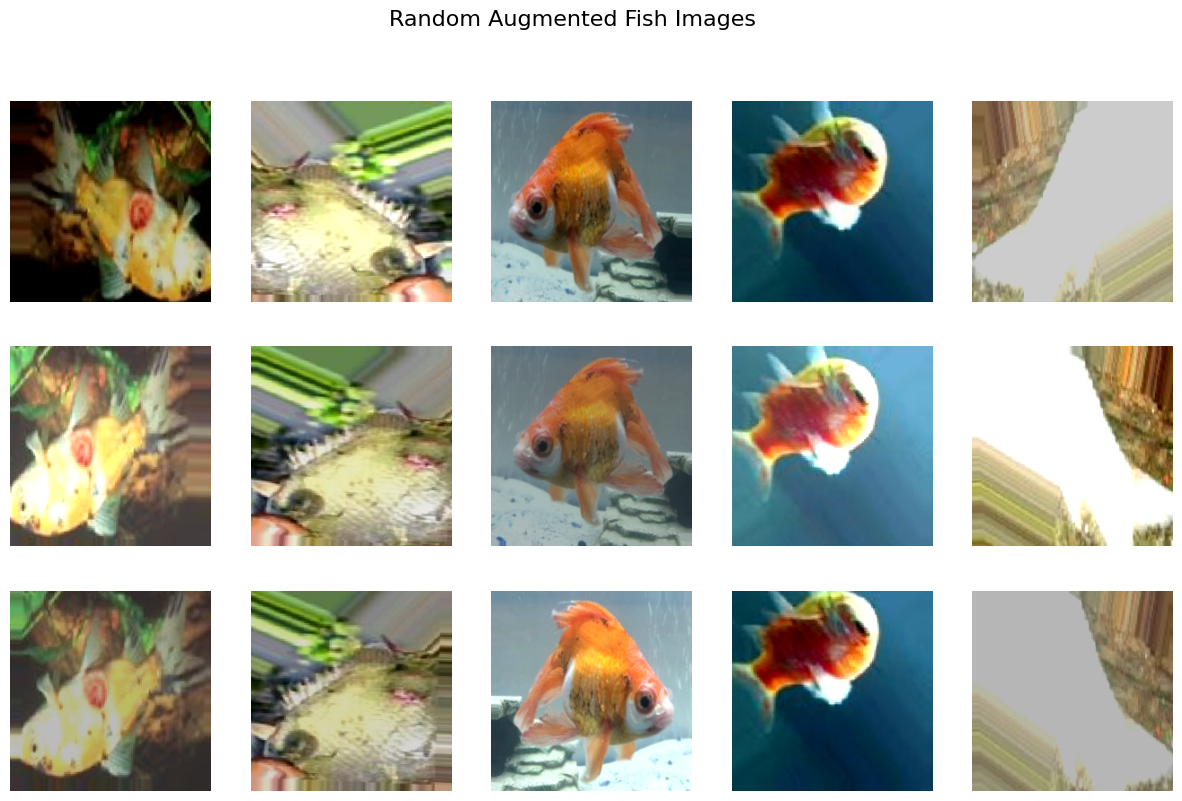

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import img_to_array, load_img
import random

NUM_IMAGES = 5
AUG_PER_IMAGE = 3

plt.figure(figsize=(NUM_IMAGES * 3, AUG_PER_IMAGE * 3))

for i in range(NUM_IMAGES):
    sample_path = random.choice(train_df['filename'].tolist())
    img = load_img(sample_path, target_size=IMG_SIZE)
    x = img_to_array(img)
    x = np.expand_dims(x, axis=0)

    aug_iter = train_datagen_cnn.flow(x, batch_size=1)

    for j in range(AUG_PER_IMAGE):
        batch = next(aug_iter)
        augmented_img = batch[0] * 255
        augmented_img = augmented_img.astype('uint8')

        plt.subplot(AUG_PER_IMAGE, NUM_IMAGES, j * NUM_IMAGES + i + 1)
        plt.imshow(augmented_img)
        plt.axis('off')

plt.suptitle("Random Augmented Fish Images", fontsize=16)
plt.show()


In [ ]:
baseline_cnn.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=[metrics.SparseCategoricalAccuracy()]
)

In [ ]:
EPOCHS = 20
history = baseline_cnn.fit(
    train_generator_cnn,
    validation_data=test_generator_cnn,
    epochs=EPOCHS
)

c:\Users\roman\anaconda3\envs\myenv\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 41s 874ms/step - loss: 2.0415 - sparse_categorical_accuracy: 0.1346 - val_loss: 1.9459 - val_sparse_categorical_accuracy: 0.1429
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 39s 893ms/step - loss: 1.9472 - sparse_categorical_accuracy: 0.1389 - val_loss: 1.9452 - val_sparse_categorical_accuracy: 0.1429
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 36s 814ms/step - loss: 1.9409 - sparse_categorical_accuracy: 0.1525 - val_loss: 1.8937 - val_sparse_categorical_accuracy: 0.1743
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 36s 805ms/step - loss: 1.8008 - sparse_categorical_accuracy: 0.2598 - val_loss: 1.6905 - val_sparse_categorical_accuracy: 0.2914
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 36s 824ms/step - loss: 1.7110 - sparse_categorical_accuracy: 0.2892 - val_loss: 1.6733 - val_sparse_categorical_accuracy: 0.3114
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 38s 865ms/step - loss: 1.5555 - sparse_categorical_accuracy: 0.3479 - val_loss: 1.4930 - val_sparse_categorical_accuracy: 0.334

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 125ms/step


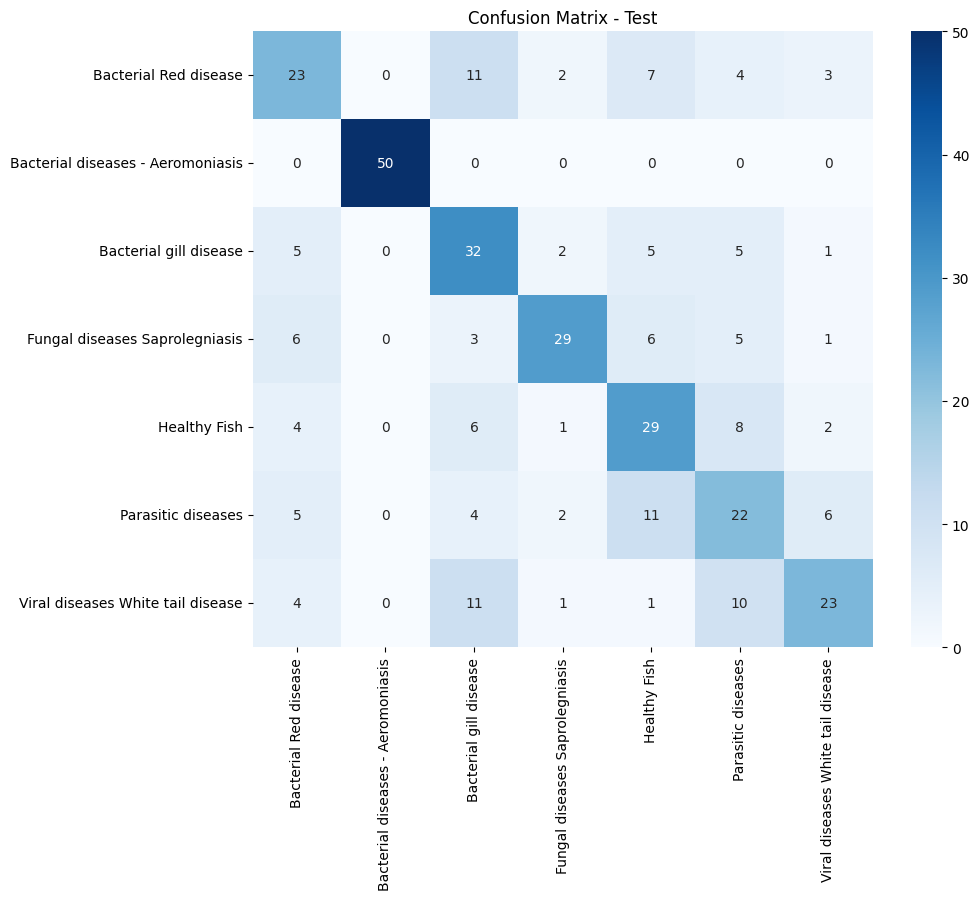

                                   precision    recall  f1-score   support

            Bacterial Red disease       0.49      0.46      0.47        50
Bacterial diseases - Aeromoniasis       1.00      1.00      1.00        50
           Bacterial gill disease       0.48      0.64      0.55        50
   Fungal diseases Saprolegniasis       0.78      0.58      0.67        50
                     Healthy Fish       0.49      0.58      0.53        50
               Parasitic diseases       0.41      0.44      0.42        50
Viral diseases White tail disease       0.64      0.46      0.53        50

                         accuracy                           0.59       350
                        macro avg       0.61      0.59      0.60       350
                     weighted avg       0.61      0.59      0.60       350

Test Accuracy: 0.5943


In [ ]:
import math
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

y_pred_probs = baseline_cnn.predict(test_generator_cnn)
y_pred = np.argmax(y_pred_probs, axis=1)

y_true = test_generator_cnn.classes

cf_mx = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10,8))
sns.heatmap(cf_mx, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues')
plt.title("Confusion Matrix - Test")
plt.show()

print(classification_report(y_true, y_pred, target_names=classes))

acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {acc:.4f}")


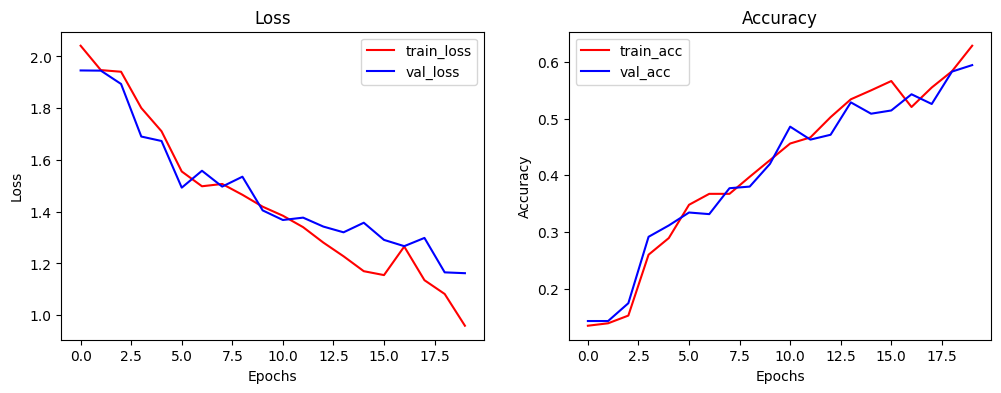

In [ ]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train_loss', color='red')
plt.plot(history.history['val_loss'], label='val_loss', color='blue')
plt.title("Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['sparse_categorical_accuracy'], label='train_acc', color='red')
plt.plot(history.history['val_sparse_categorical_accuracy'], label='val_acc', color='blue')
plt.title("Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


In [ ]:
from tensorflow.keras import layers, models, regularizers

NUM_CLASSES = len(classes)
IMG_SHAPE = (224, 224, 3)

baseline_cnn_optimized = models.Sequential([

    layers.Input(shape=IMG_SHAPE),

    # Block 1
    layers.Conv2D(96, (11,11), strides=(4,4), padding='valid',
                  kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((3,3), strides=2),

    # Block 2
    layers.Conv2D(256, (5,5), padding='same',
                  kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((3,3), strides=2),

    # Block 3
    layers.Conv2D(384, (3,3), padding='same',
                  kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.ReLU(),

    layers.Conv2D(256, (3,3), padding='same',
                  kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.ReLU(),

    layers.MaxPooling2D((3,3), strides=2),

    # Fully connected
    layers.Flatten(),

    layers.Dense(1024, activation=None, kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Dropout(0.1),

    layers.Dense(1024, activation=None, kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Dropout(0.1),

    layers.Dense(NUM_CLASSES, activation='softmax')
])

baseline_cnn_optimized.summary()


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_21 (Conv2D)              │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 54, 54, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_17 (ReLU)                 │ (None, 54, 54, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 26, 26, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_18 (ReLU)                 │ (None, 26, 26, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 12, 12, 384)    │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_19 (ReLU)                 │ (None, 12, 12, 384)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_20 (ReLU)                 │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1024)           │     6,554,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_21 (ReLU)                 │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │             

 Total params: 10,043,271 (38.31 MB)

 Trainable params: 10,037,191 (38.29 MB)

 Non-trainable params: 6,080 (23.75 KB)

In [ ]:
baseline_cnn_optimized.compile(
    optimizer=optimizers.Adam(learning_rate=0.0005),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=[metrics.SparseCategoricalAccuracy()]
)

In [ ]:
EPOCHS = 20
history = baseline_cnn_optimized.fit(
    train_generator_cnn,
    validation_data=test_generator_cnn,
    epochs=EPOCHS
)

Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 46s 977ms/step - loss: 1.7641 - sparse_categorical_accuracy: 0.4102 - val_loss: 5.7637 - val_sparse_categorical_accuracy: 0.1657
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 82s 979ms/step - loss: 1.3711 - sparse_categorical_accuracy: 0.5032 - val_loss: 3.0302 - val_sparse_categorical_accuracy: 0.2914
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 44s 985ms/step - loss: 1.2262 - sparse_categorical_accuracy: 0.5490 - val_loss: 1.7913 - val_sparse_categorical_accuracy: 0.3743
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - loss: 1.0784 - sparse_categorical_accuracy: 0.5956 - val_loss: 3.2853 - val_sparse_categorical_accuracy: 0.2857
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 42s 953ms/step - loss: 0.9514 - sparse_categorical_accuracy: 0.6485 - val_loss: 1.2640 - val_sparse_categorical_accuracy: 0.5743
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 40s 896ms/step - loss: 0.8905 - sparse_categorical_accuracy: 0.6807 - val_loss: 1.7223 - val_sparse_categorical_accuracy: 0.4571
E

11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 230ms/step


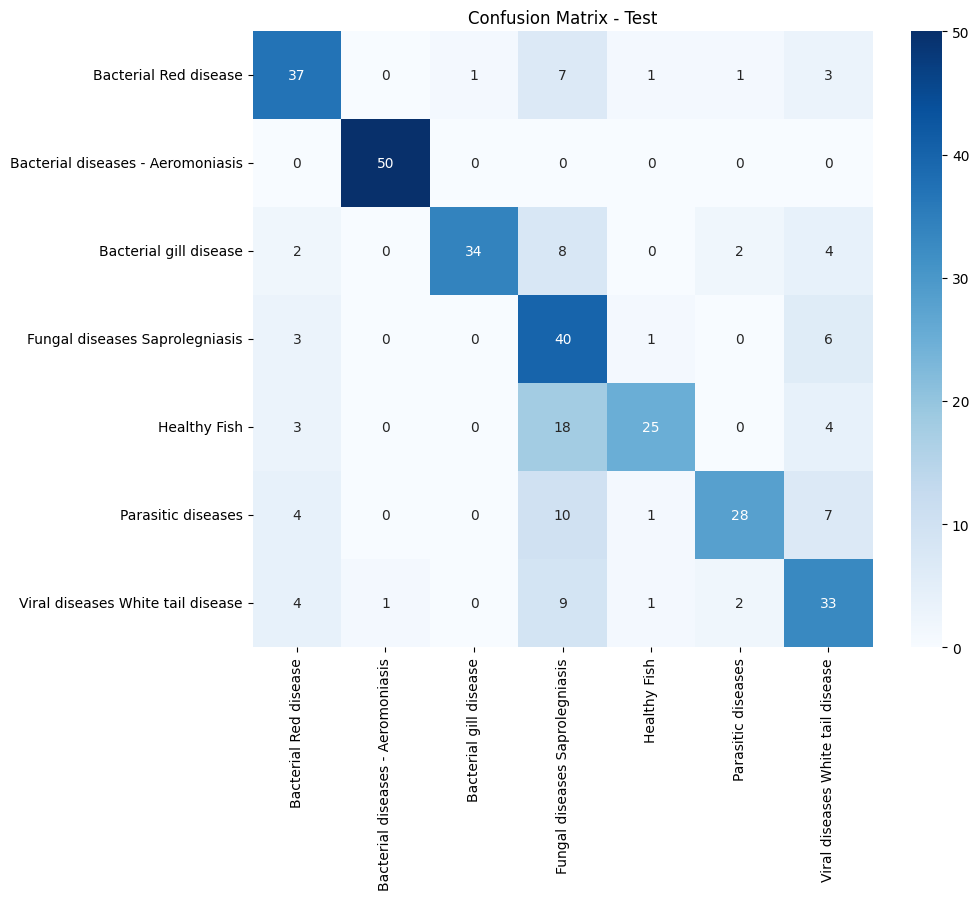

                                   precision    recall  f1-score   support

            Bacterial Red disease       0.70      0.74      0.72        50
Bacterial diseases - Aeromoniasis       0.98      1.00      0.99        50
           Bacterial gill disease       0.97      0.68      0.80        50
   Fungal diseases Saprolegniasis       0.43      0.80      0.56        50
                     Healthy Fish       0.86      0.50      0.63        50
               Parasitic diseases       0.85      0.56      0.67        50
Viral diseases White tail disease       0.58      0.66      0.62        50

                         accuracy                           0.71       350
                        macro avg       0.77      0.71      0.71       350
                     weighted avg       0.77      0.71      0.71       350

Test Accuracy: 0.7057


In [ ]:
import math
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

y_pred_probs = baseline_cnn_optimized.predict(test_generator_cnn)
y_pred = np.argmax(y_pred_probs, axis=1)

y_true = test_generator_cnn.classes

cf_mx = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10,8))
sns.heatmap(cf_mx, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues')
plt.title("Confusion Matrix - Test")
plt.show()

print(classification_report(y_true, y_pred, target_names=classes))

acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {acc:.4f}")


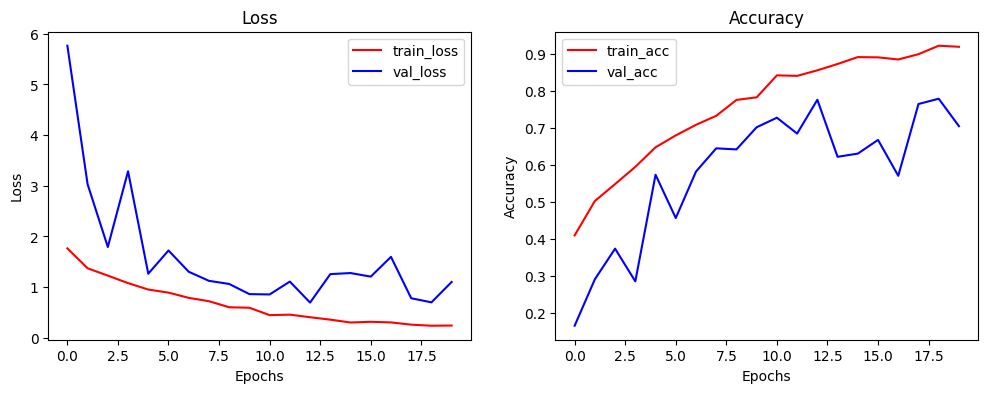

In [ ]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train_loss', color='red')
plt.plot(history.history['val_loss'], label='val_loss', color='blue')
plt.title("Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['sparse_categorical_accuracy'], label='train_acc', color='red')
plt.plot(history.history['val_sparse_categorical_accuracy'], label='val_acc', color='blue')
plt.title("Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


*1. Optimized Alex-Net*

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step


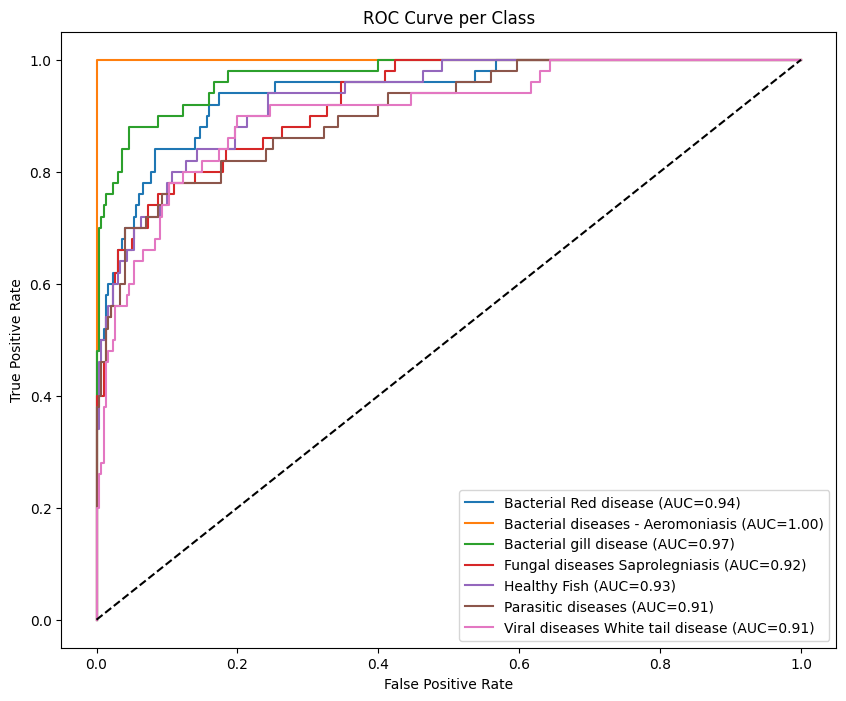

AUC for Bacterial Red disease: 0.9431
AUC for Bacterial diseases - Aeromoniasis: 1.0000
AUC for Bacterial gill disease: 0.9718
AUC for Fungal diseases Saprolegniasis: 0.9231
AUC for Healthy Fish: 0.9307
AUC for Parasitic diseases: 0.9058
AUC for Viral diseases White tail disease: 0.9064


In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score, roc_curve

num_classes = len(classes)

y_true_raw = test_generator_cnn.classes
y_true_bin = label_binarize(y_true_raw, classes=np.arange(num_classes))

steps = math.ceil(test_generator_cnn.samples / test_generator_cnn.batch_size)
y_pred_probs = baseline_cnn_optimized.predict(test_generator_cnn, steps=steps)

min_len = min(len(y_true_bin), len(y_pred_probs))
y_true_bin = y_true_bin[:min_len]
y_pred_probs = y_pred_probs[:min_len]

plt.figure(figsize=(10,8))

auc_scores = []
for i in range(num_classes):
    auc = roc_auc_score(y_true_bin[:, i], y_pred_probs[:, i])
    auc_scores.append(auc)

    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
    plt.plot(fpr, tpr, label=f"{classes[i]} (AUC={auc:.2f})")

plt.plot([0,1], [0,1], 'k--')
plt.title("ROC Curve per Class")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

for i, auc in enumerate(auc_scores):
    print(f"AUC for {classes[i]}: {auc:.4f}")


*2. Original Alex-Net*

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step


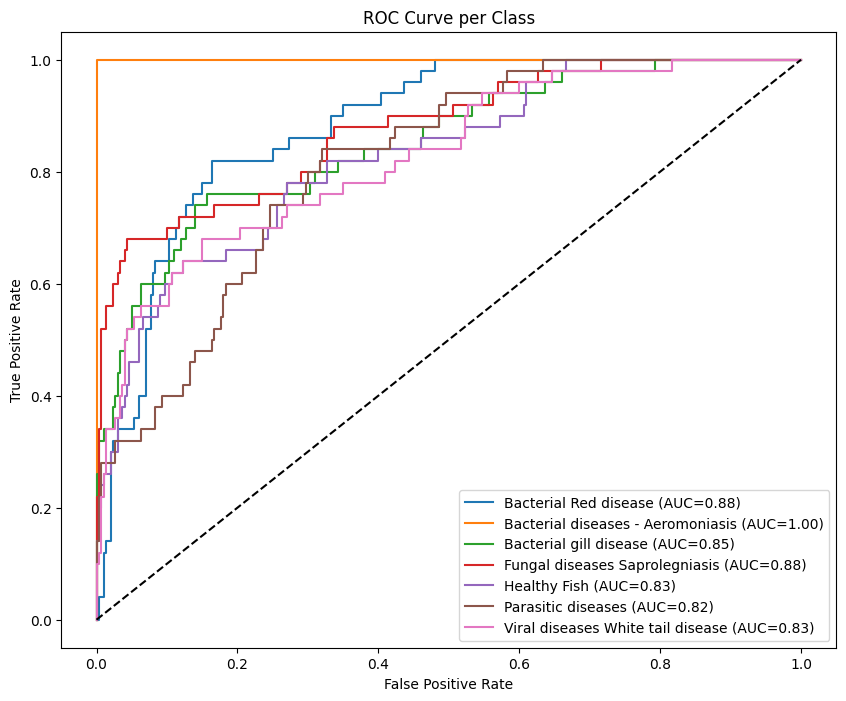

AUC for Bacterial Red disease: 0.8833
AUC for Bacterial diseases - Aeromoniasis: 1.0000
AUC for Bacterial gill disease: 0.8510
AUC for Fungal diseases Saprolegniasis: 0.8765
AUC for Healthy Fish: 0.8282
AUC for Parasitic diseases: 0.8151
AUC for Viral diseases White tail disease: 0.8265


In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score, roc_curve

num_classes = len(classes)

y_true_raw = test_generator_cnn.classes
y_true_bin = label_binarize(y_true_raw, classes=np.arange(num_classes))

steps = math.ceil(test_generator_cnn.samples / test_generator_cnn.batch_size)
y_pred_probs = baseline_cnn.predict(test_generator_cnn, steps=steps)

min_len = min(len(y_true_bin), len(y_pred_probs))
y_true_bin = y_true_bin[:min_len]
y_pred_probs = y_pred_probs[:min_len]

plt.figure(figsize=(10,8))

auc_scores = []
for i in range(num_classes):
    auc = roc_auc_score(y_true_bin[:, i], y_pred_probs[:, i])
    auc_scores.append(auc)

    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
    plt.plot(fpr, tpr, label=f"{classes[i]} (AUC={auc:.2f})")

plt.plot([0,1], [0,1], 'k--')
plt.title("ROC Curve per Class")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

for i, auc in enumerate(auc_scores):
    print(f"AUC for {classes[i]}: {auc:.4f}")


*3. Transfer Learning*

11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step


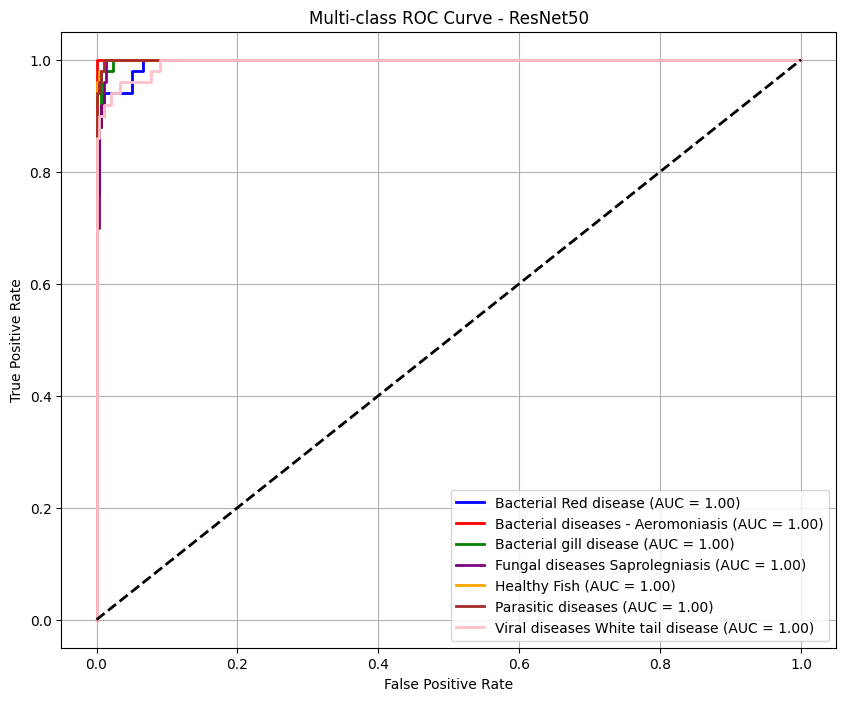

In [ ]:
import math
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc as sk_auc
import matplotlib.pyplot as plt
from itertools import cycle

steps = math.ceil(test_generator.samples / test_generator.batch_size)
y_pred_probs = model.predict(test_generator, steps=steps)

y_pred_probs = y_pred_probs[: test_generator.samples]

y_true = test_generator.classes
num_classes = len(classes)

y_true_bin = label_binarize(y_true, classes=list(range(num_classes)))


fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
    roc_auc[i] = sk_auc(fpr[i], tpr[i])


plt.figure(figsize=(10, 8))
colors = cycle(["blue", "red", "green", "purple", "orange", "brown", "pink"])

for i, color in zip(range(num_classes), colors):
    plt.plot(
        fpr[i],
        tpr[i],
        lw=2,
        color=color,
        label=f"{classes[i]} (AUC = {roc_auc[i]:.2f})"
    )

plt.plot([0, 1], [0, 1], "k--", lw=2)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-class ROC Curve - ResNet50")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

**ESSAY ANSWERS**

*3a. Issues with the image dataset include: imbalanced data (one particular class only has 6 images, whereas on average there are over 220 images per class); a low level of fish variability (which could only be addressed through augmentation, as adding images from external sources would mean data fabrication) leading to overly optimistic metrics; low-quality or corrupted images (blurry, pixelated, or low-resolution, which was fixed through configurations in ImageGenerator); uneven image sizes that could distort objects (solved through cropping); and redundant or duplicate images resulting in poor generalizations.*

*3b. The data is already trained. Based on the validation loss graph, it shows high and unstable loss. Both the training and validation losses start high (near 2.0) and decrease slowly, but the validation loss remains consistently higher than the training loss after epoch 5. This indicates a potential for overfitting. The model's accuracy levels off around 60%, suggesting that the model is highly biased, making it not complex or powerful enough to correctly model the underlying relationships, regardless of additional training.*

*3c. For improvements on the AlexNet, I added Batch Normalization after every single convolutional and dense layer (before the activation). This normalizes the output of the previous layer by subtracting the batch mean and dividing by the batch standard deviation. This significantly reduces the internal covariate shift, enabling the network to use higher learning rates, which speeds up training and leads to better final performance.*

*I also separated the layers as Conv2D -> BatchNormalization -> ReLU(). While Keras often handles the order, placing layers in this specific sequence is the most effective practice to ensure that the normalized values are passed to the non-linearity.*

*I also explicitly set kernel_initializer = 'he_normal' for all convolutional and dense layers, since He initialization is specifically designed for layers using the ReLU activation function. It mitigates gradients from exploding or vanishing by maintaining the variance of activations across layers.*

*Improvements include an increase by 10% in test accuracy, improved recall for the majority of classes, and the prevention of co-adaptation of neurons.*

*3d. I used ResNet50 for transfer learning. Compared to the other two models on the validation set, ResNet50 proves to be a robust model, attributing its near-perfect title to its high test accuracy and recall*

*The overall accuracy is 95%, meaning 95 out of every 100 predictions the ResNet50 model makes are correct across all seven classes. Given the improved recall (from 0.84 to 1), this model manages to identify a higher number of disease incidences at a better rate compared to the previous models. Moreover, it also has more improved precision, leading to correct predictions of disease cases.*

*The model also manages to maintain an excellent balance between balance and precision given the high F1 score*

**However, it is important to consider that these results arise from image datasets with a high similarity level. Not much contrivance could be made to increase the diversity of the fish profiles other than reconfiguring the images. Such a model should be retrained on a dataset from a more hostile or harsher profile ecosystem.**

 *For the numerical evidence, you could check the graph presented under the code blocks.*

*3e. For the image of the metrics, refer to the visuals below the code blocks for each model.*

*The comparison table for this answer is available in image 3e.jpg*